# EDUCATION PROJECT

### Research question: Can socioeconomic factors predict a school's average ACT score? We also investigate whether adding charter school status improves predictions.

This notebook continues the work in the separate data-preparation notebook, which loads and joins the original EdGap data and the Common Core of Data (CCD) school information. The prepared file is education_clean.csv. We use exploratory plots and simple linear regression to answer the question. Relationships in this analysis are associations, not evidence of causation.

# Import libraries

In [4]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data

In [6]:
df = pd.read_csv("/Users/linhchung/Documents/GitHub/Education-Project/data/education_clean.csv")

In [7]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


# Exploratory data analysis

## Examine distributions and relationships

### Plot the correlation matrix of the numerical variables in the data to explore relationships between the variables.

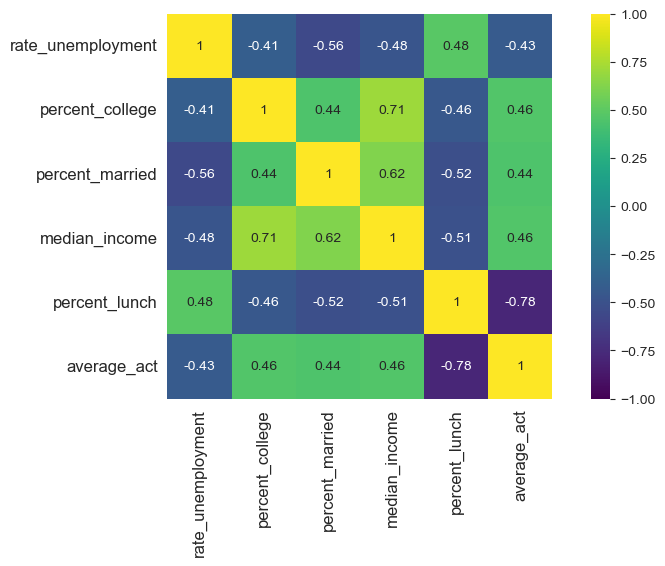

In [11]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

We will look at the correlation between average_act and the predictor variables, as well as the correlation among those predictor variables.

### Make pair plots to explore relationships between the variables.

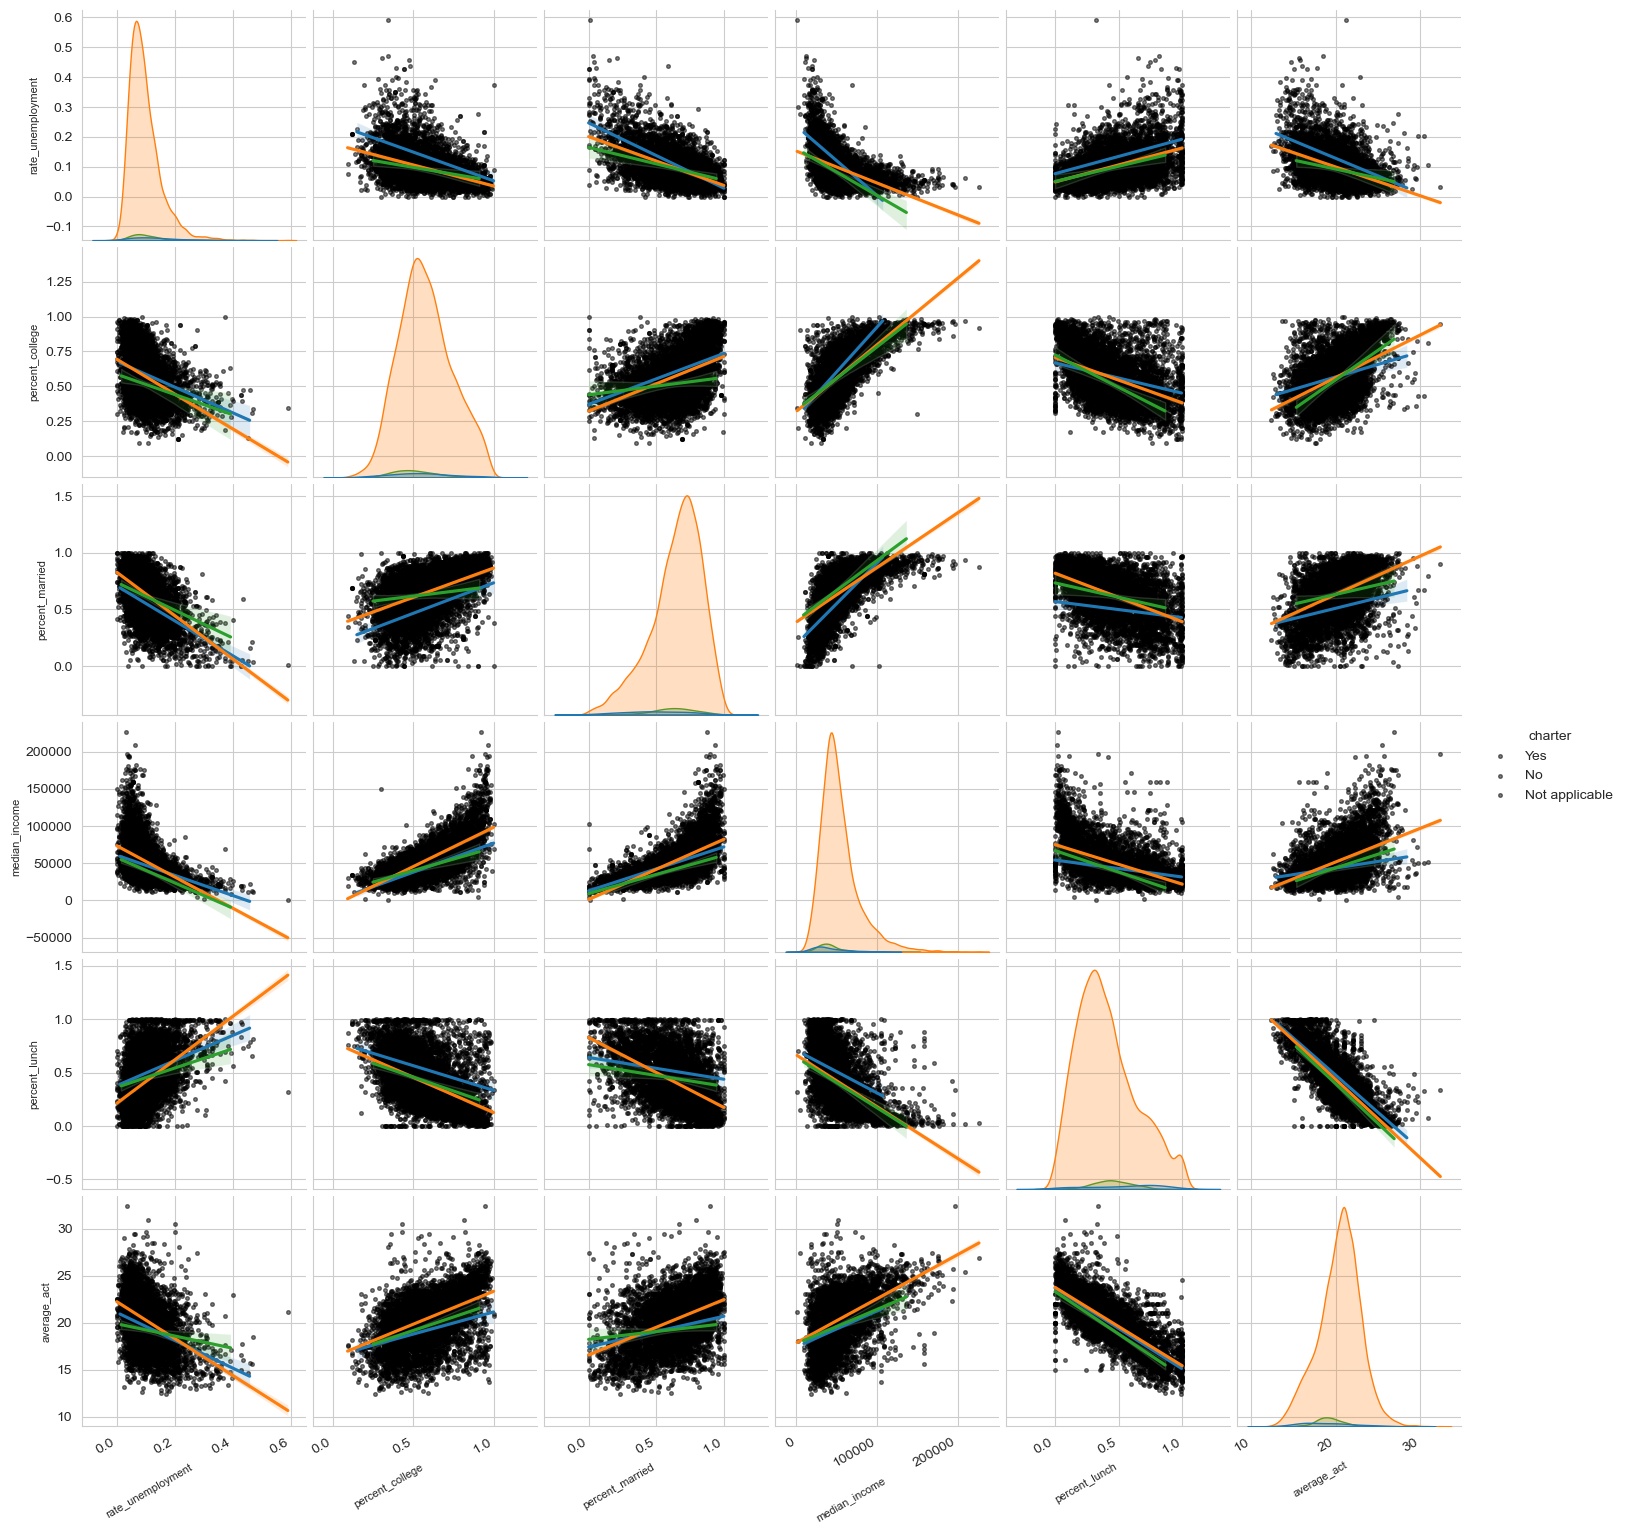

In [14]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

### Identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median income is on a very different scale than the other predictors, so we will make two plots to explore the data.

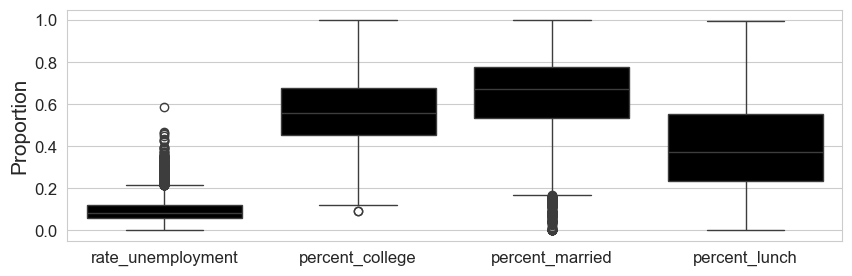

In [17]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

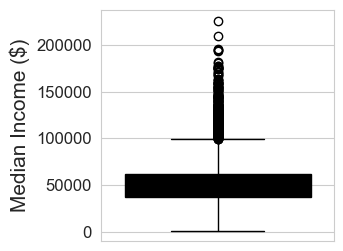

In [18]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

## Summary
1. The numerical predictors are related to average_act. The relationships appear roughly linear.
2. The numerical predictors are correlated with each other, suggesting that not all predictors will be necessary.
3. Some variables have skewed distributions, suggesting that transformations of input variables might be useful.
4. There are outliers in rate_unemployment, percent_college, percent_married and median_income. None of these are obviously incorrect values; they likely reflect skewed distributions. We may consider applying something like a log transformation to these predictors as we explore different models.
5. The relationships are similar across charter and non-charter schools, but might be significantly different.

## Additional analysis: check the data

The following cells extend the original EDA without replacing its code. First we check the data types, missing values, and the relationship between ACT scores and the predictors.

In [21]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df[['average_act', 'rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']].describe())

(7227, 13)
id                     int64
rate_unemployment    float64
percent_college      float64
percent_married      float64
median_income        float64
average_act          float64
percent_lunch        float64
year                  object
state                 object
zip_code               int64
school_type           object
school_level          object
charter               object
dtype: object
id                   0
rate_unemployment    0
percent_college      0
percent_married      0
median_income        0
average_act          0
percent_lunch        0
year                 0
state                0
zip_code             0
school_type          0
school_level         0
charter              0
dtype: int64
       average_act  rate_unemployment  percent_college  percent_married  \
count  7227.000000        7227.000000      7227.000000      7227.000000   
mean     20.298577           0.096456         0.573005         0.640350   
std       2.508415           0.056581         0.164926       

The table above helps us confirm how many schools are included and whether any variables still have missing values. Missing charter values will be excluded only from the model that uses charter status.

In [23]:
act_correlations = df[['average_act', 'rate_unemployment', 'percent_college',
                       'percent_married', 'median_income', 'percent_lunch']].corr()
print(act_correlations['average_act'].sort_values())

percent_lunch       -0.783530
rate_unemployment   -0.433243
percent_married      0.439825
percent_college      0.458367
median_income        0.459550
average_act          1.000000
Name: average_act, dtype: float64


The correlations show which factors have positive or negative associations with ACT scores. A negative correlation means higher values of that factor tend to occur alongside lower ACT scores; it does not show that the factor causes lower scores.

## Derived variables

The data preparation file may already include transformed variables. Here we calculate two simple versions again for clarity: median income in units of $10,000 and lunch participation in percentage points.

In [26]:
df['income_10k'] = df['median_income'] / 10000
df['lunch_pct_points'] = df['percent_lunch'] * 100
print(df[['median_income', 'income_10k', 'percent_lunch', 'lunch_pct_points']].head())

   median_income  income_10k  percent_lunch  lunch_pct_points
0        42820.0      4.2820       0.066901          6.690141
1        89320.0      8.9320       0.112412         11.241218
2        84140.0      8.4140       0.096816          9.681611
3        56500.0      5.6500       0.296960         29.696025
4        54015.0      5.4015       0.262641         26.264114


The derived variables use more convenient units, but they represent the same underlying information. We will use them in the regression models instead of their original versions.

## Predict average ACT scores

We use linear regression to see whether socioeconomic factors help predict ACT scores. We split the data into training and testing sets, so we evaluate the model on schools that were not used to fit it. We use the same schools and split for both models to make the comparison fair.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

factors = ['rate_unemployment', 'percent_college', 'percent_married',
           'income_10k', 'lunch_pct_points']

# Use rows with complete information for both models.
model_data = df[factors + ['average_act', 'charter']].dropna().copy()
model_data['charter_yes'] = (model_data['charter'] == 'Yes').astype(int)

train_data, test_data = train_test_split(model_data, test_size=0.2, random_state=42)

X_train = train_data[factors]
X_test = test_data[factors]
y_train = train_data['average_act']
y_test = test_data['average_act']

model1 = LinearRegression()
model1.fit(X_train, y_train)
predictions1 = model1.predict(X_test)

print('Socioeconomic factors only')
print('MAE:', round(mean_absolute_error(y_test, predictions1), 3))
print('RMSE:', round(mean_squared_error(y_test, predictions1) ** 0.5, 3))
print('R-squared:', round(r2_score(y_test, predictions1), 3))

Socioeconomic factors only
MAE: 1.161
RMSE: 1.554
R-squared: 0.615


The second model adds a variable that is 1 for charter schools and 0 for non-charter schools. Comparing its test errors with the first model helps us see whether this additional predictor improves predictions.

In [32]:
from sklearn.linear_model import LinearRegression

factors_with_charter = factors + ['charter_yes']

model2 = LinearRegression()

model2.fit(train_data[factors_with_charter], y_train)

predictions2 = model2.predict(test_data[factors_with_charter])

print("Model 2 completed successfully")

Model 2 completed successfully


                             model    MAE   RMSE  R_squared
0            Socioeconomic factors  1.161  1.554      0.615
1  Socioeconomic factors + charter  1.161  1.554      0.615


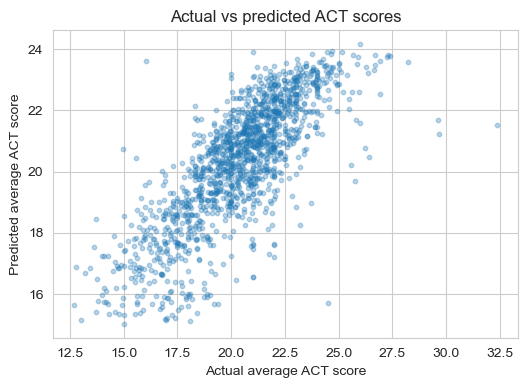

In [34]:
results = pd.DataFrame({
    'model': ['Socioeconomic factors', 'Socioeconomic factors + charter'],
    'MAE': [mean_absolute_error(y_test, predictions1), mean_absolute_error(y_test, predictions2)],
    'RMSE': [mean_squared_error(y_test, predictions1) ** 0.5,
             mean_squared_error(y_test, predictions2) ** 0.5],
    'R_squared': [r2_score(y_test, predictions1), r2_score(y_test, predictions2)]
})
print(results.round(3))

plt.figure(figsize=(6, 4))
plt.scatter(y_test, predictions1, alpha=0.3, s=10)
plt.xlabel('Actual average ACT score')
plt.ylabel('Predicted average ACT score')
plt.title('Actual vs predicted ACT scores')
plt.show()

In [43]:
print("Model 1 predictors:", factors)
print("Model 2 predictors:", factors_with_charter)

print("Charter values:")
print(df['charter'].value_counts())

Model 1 predictors: ['rate_unemployment', 'percent_college', 'percent_married', 'income_10k', 'lunch_pct_points']
Model 2 predictors: ['rate_unemployment', 'percent_college', 'percent_married', 'income_10k', 'lunch_pct_points', 'charter_yes']
Charter values:
charter
No                6858
Not applicable     199
Yes                170
Name: count, dtype: int64


### Additional Predictor: Charter School Status

In this analysis, I included charter school status as an additional predictor to investigate whether school type improves predictions of average ACT scores.

The dataset contains 6,858 non-charter schools, 170 charter schools, and 199 schools where charter status is marked as not applicable. Charter schools represent only about 2.4% of the dataset.

The results show that adding charter school status did not noticeably improve the model's performance. Both models achieved an R-squared value of 0.615 and an RMSE of 1.554.

One possible explanation is that charter schools make up a small proportion of the dataset. Overall, socioeconomic factors appear to be more useful for predicting average ACT scores in this analysis.

## Conclusion

The regression results above show how accurately socioeconomic factors predict average ACT scores for the held-out schools. Compare the two rows in the results table: if the model with charter status has lower MAE and RMSE, it performs better on this test set; otherwise, charter status did not improve predictions on this split. The scatterplot shows how close predicted ACT scores are to the actual scores.

This analysis identifies associations rather than causal effects. It also has limitations: schools with missing charter information were excluded from the model comparison, and a single train/test split cannot establish how well results will generalize to all schools. The preparation steps and their limitations are documented in the separate data-preparation notebook.